In [28]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
# Chọn một tệp dữ liệu mẫu.
file = Path("car_data/20180713-home2mimos.csv")
# file = Path("car_data/20180713-mimos2home.csv")
lines = file.read_text(encoding="utf-8-sig").splitlines()

# Tìm dòng kết thúc metadata và lấy tên các kênh.
log_index = next(
    i for i, line in enumerate(lines)
    if line.startswith("Log :")
)
columns = ["Time"] + [
    line.split(" : ", 1)[1]
    for line in lines[:log_index]
    if line.startswith("Channel :")
]

# Đọc bảng dữ liệu, bỏ qua metadata.
df1 = pd.read_csv(file, skiprows=log_index + 1, names=columns)

# print("Số dòng, số cột:", df1.shape)
# df1.head()

# Kiểu dữ liệu và số giá trị có mặt trong từng cột
# df1.info()

In [29]:
print("\n".join(lines[:log_index + 1]))

%DataLog%
DataLogVersion : 1.0
Software : ECU Manager
SoftwareVersion : 1.1.14.0
DownloadDateTime : 20180713 08:37:23
Channel : BaseFuel
Type : Percentage
DisplayMaxMin : 2000,0
Channel : BaseIgnition
Type : AngleIgnSprt2K
DisplayMaxMin : 800,0
Channel : TargetAFR
Type : AFR
DisplayMaxMin : 2000,200
Channel : FuelCoolantTempCorrection
Type : Percentage1For1
DisplayMaxMin : 250,-100
Channel : FuelAirTempCorrection
Type : Percentage
DisplayMaxMin : 500,-500
Channel : ThrottlePosition
Type : Percentage
DisplayMaxMin : 1000,0
Channel : AirTemp
Type : Temperature
DisplayMaxMin : 4231,2331
Channel : CoolantTemp
Type : Temperature
DisplayMaxMin : 4231,2331
Channel : LambdaSensor1
Type : AFR
DisplayMaxMin : 2000,200
Channel : RPM
Type : EngineSpeed
DisplayMaxMin : 10000,0
Channel : Load
Type : Pressure
DisplayMaxMin : 1013,13
Channel : BatteryVoltage
Type : BatteryVoltage
DisplayMaxMin : 16000,8000
Channel : EngineRunningTime
Type : Time_s
DisplayMaxMin : 10000,0
Channel : DeltaLoad
Type : Per

In [30]:
df_work = df1.copy()

# Giữ thông tin nguồn và thứ tự bản ghi
df_work["trip_id"] = file.stem
df_work["source_row"] = range(len(df_work))

# Chuyển thời gian, giữ nguyên cột Time ban đầu
df_work["time_parsed"] = pd.to_timedelta(
    df_work["Time"], errors="coerce"
)

df_work["elapsed_s"] = (
    df_work["time_parsed"] - df_work["time_parsed"].iloc[0]
).dt.total_seconds()

df_work["dt_s"] = df_work["elapsed_s"].diff()

# Đánh dấu để kiểm tra, chưa xóa bản ghi
df_work["duplicate_time"] = df_work["Time"].duplicated(
    keep=False
)
df_work["time_backwards"] = df_work["dt_s"].lt(0)

df_work[["Time", "elapsed_s", "RPM"]].head(10)

,Time,elapsed_s,RPM
0,07:54:58.000,0.000,1164.0
1,07:54:58.031,0.031,1155.0
2,07:54:58.047,0.047,NaN
3,07:54:58.062,0.062,1168.0
4,07:54:58.078,0.078,NaN
5,07:54:58.109,0.109,NaN
6,07:54:58.140,0.140,1168.0
7,07:54:58.156,0.156,1169.0
8,07:54:58.250,0.250,1174.0
9,07:54:58.265,0.265,1180.0


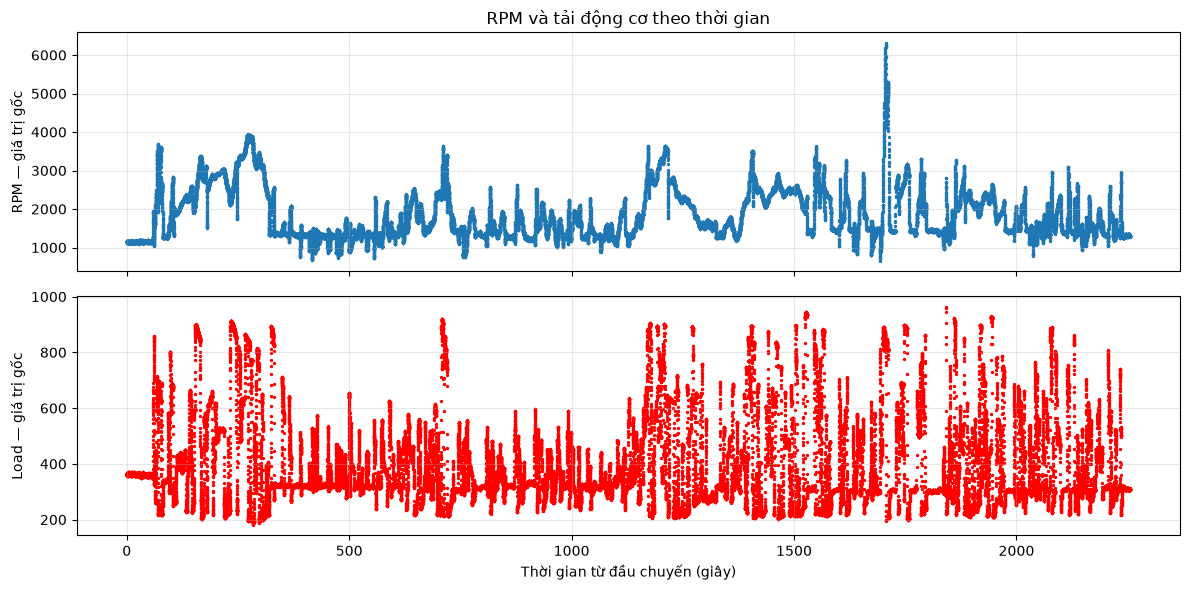

In [31]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].scatter(df_work["elapsed_s"], df_work["RPM"], s=2)
axes[0].set_ylabel("RPM — giá trị gốc")
axes[0].set_title("RPM và tải động cơ theo thời gian")

axes[1].scatter(df_work["elapsed_s"], df_work["Load"], color='red', s=2)
axes[1].set_ylabel("Load — giá trị gốc")
axes[1].set_xlabel("Thời gian từ đầu chuyến (giây)")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

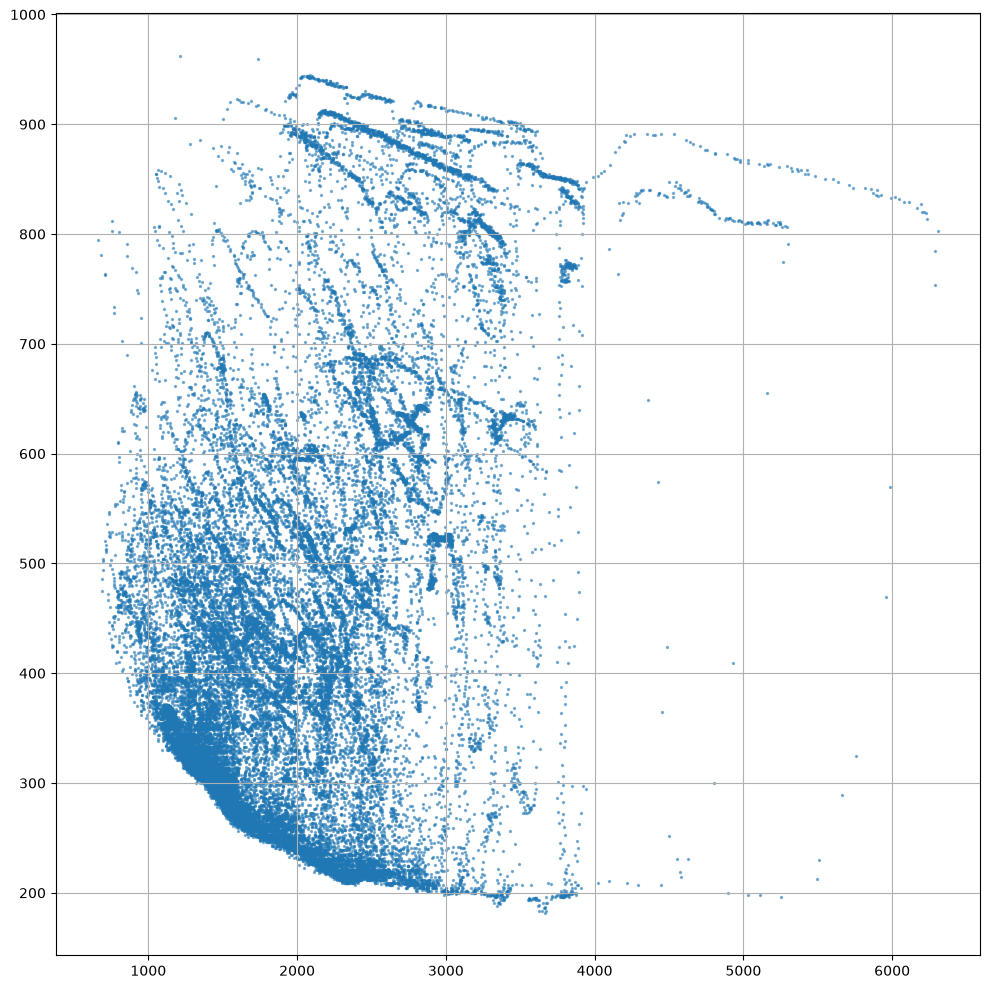

In [32]:
plt.figure(figsize=(10, 10))

plt.scatter(
    df_work["RPM"], df_work["Load"],
    s=2, alpha=0.5, label="RPM - Load"
)
plt.grid()
plt.tight_layout()
plt.show()

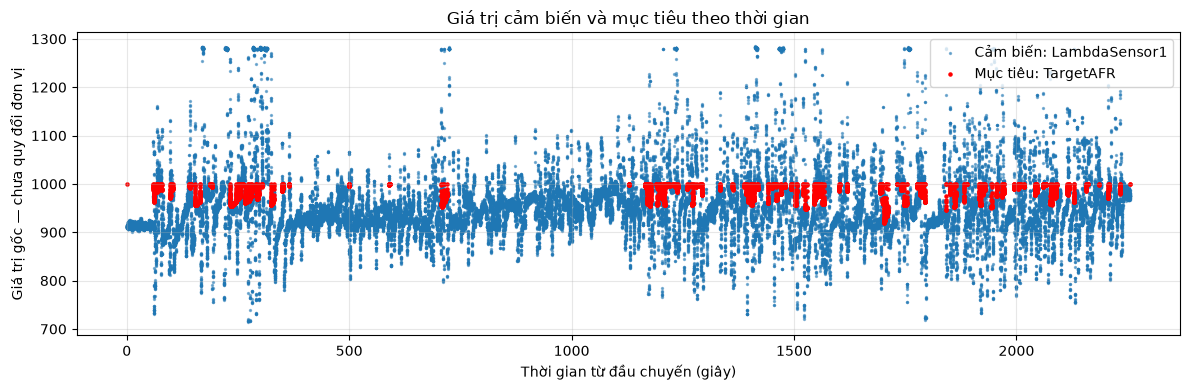

In [33]:
plt.figure(figsize=(12, 4))

plt.scatter(
    df_work["elapsed_s"], df_work["LambdaSensor1"],
    s=2, alpha=0.5, label="Cảm biến: LambdaSensor1"
)
plt.scatter(
    df_work["elapsed_s"], df_work["TargetAFR"],
    s=5, color="red", label="Mục tiêu: TargetAFR"
)

plt.xlabel("Thời gian từ đầu chuyến (giây)")
plt.ylabel("Giá trị gốc — chưa quy đổi đơn vị")
plt.title("Giá trị cảm biến và mục tiêu theo thời gian")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
channels = [
    "RPM", "Load", "BaseFuel",
    "TargetAFR", "LambdaSensor1",
    "CoolantTemp", "ThrottlePosition"
]

records = []

for col in channels:
    observed_time = df_work.loc[
        df_work[col].notna(), "elapsed_s"
    ]
    gaps = observed_time.diff().dropna()

    records.append({
        "channel": col,
        "observed_count": len(observed_time),
        "missing_pct": df_work[col].isna().mean() * 100,
        "median_gap_s": gaps.median(),
        "p95_gap_s": gaps.quantile(0.95),
        "max_gap_s": gaps.max(),
    })

channel_report = pd.DataFrame(records)
channel_report.round(3)

,channel,observed_count,missing_pct,median_gap_s,p95_gap_s,max_gap_s
0,RPM,60088,12.194,0.031,0.078,1.593
1,Load,52932,22.651,0.032,0.094,1.593
2,BaseFuel,50200,26.644,0.032,0.094,6.046
3,TargetAFR,3836,94.395,0.047,0.484,408.218
4,LambdaSensor1,58487,14.534,0.031,0.078,1.593
5,CoolantTemp,19151,72.015,0.047,0.563,13.343
6,ThrottlePosition,27996,59.090,0.046,0.235,13.140


In [35]:
check_columns = [
    "RPM", "Load", "BaseFuel",
    "TargetAFR", "LambdaSensor1",
    "AirTemp", "CoolantTemp", "BatteryVoltage"
]

df_work[check_columns].describe(
    percentiles=[0.01, 0.5, 0.99]
).T.round(2)

,count,mean,std,min,1%,50%,99%,max
RPM,60088.0,1866.93,671.13,660.0,964.0,1606.0,3783.0,6308.0
Load,52932.0,410.58,166.61,182.0,212.0,339.0,896.0,962.0
BaseFuel,50200.0,418.51,104.33,282.0,291.0,357.0,668.0,782.0
TargetAFR,3836.0,978.93,16.50,920.0,933.0,981.0,1000.0,1000.0
LambdaSensor1,58487.0,952.50,69.55,715.0,808.0,943.0,1280.0,1285.0
AirTemp,20060.0,3258.73,71.21,3090.0,3093.0,3274.0,3354.0,3357.0
CoolantTemp,19151.0,3529.62,68.36,3396.0,3398.0,3550.0,3615.0,3619.0
BatteryVoltage,55468.0,12985.39,143.76,12058.0,12637.0,12997.0,13231.0,13309.0


In [36]:
afr_check = df1[
    ["TargetAFR", "LambdaSensor1", "AFRDifference"]
].dropna().copy()

afr_check["difference_calculated"] = (
    afr_check["TargetAFR"] - afr_check["LambdaSensor1"]
)

afr_check["matches"] = (
    afr_check["difference_calculated"]
    == afr_check["AFRDifference"]
)

afr_check["matches"].value_counts()

matches
True    3438
Name: count, dtype: int64